# Gene-length bias analysis

Are longer genes more (or less) likely to be up-regulated in one group than the other? Run the cells from top to bottom (Shift + Enter). Edit the lines marked `# EDIT`.

## 1. Setup and load data

In [1]:
# Load in necessary packages
import sys
import pandas as pd

sys.path.insert(0, "/Users/ryan/Desktop/gene_length")  # EDIT: folder containing gene_length_tools.py
import gene_length as glt


### Load in the gene lengths obtained from 

In [2]:
# Gene lengths -> dictionary {gene_id: length in bp}
gene_lengths = pd.read_csv("vm22_gene_lengths.csv")  # EDIT
gene_length_map = glt.make_gene_length_map(gene_lengths, id_col="geneID", length_col="gene_length")  # EDIT column names


In [3]:
# Sample table: one row per sample, row labels = sample names (must match the counts columns)
meta = pd.read_csv("raw/PND120/Cohort1/sampleTable.csv", sep="\t").set_index("sampleName")  # EDIT

# Raw counts: one row per gene, one column per sample, row labels = gene IDs
counts = pd.read_csv("raw/PND120/Cohort1/counttable.tsv", sep="\t", index_col="feature")  # EDIT
counts = counts[~counts.index.str.startswith("_")]  # drop non-gene summary rows (e.g. HTSeq "__no_feature")

## 2. Run the analysis

In [4]:
# Runs input checks, differential expression, and the gene-length statistics in one call.
# this also prints features of the data. 
    # For instance the total number of genes and the number of genes in which length information is available for

results = glt.run_gene_length_analysis(
    counts,
    meta,
    gene_length_map,
    group_col="Condition",   # EDIT: meta column holding the groups
    reference="Control",     # EDIT: baseline group
    tested="ELS",            # EDIT: group compared to baseline (logFC > 0 = higher in this group)
    # split_col="Tissue",    # optional: run separately for each value of a meta column. This is useful is there are multiple regions/tissue in the metadata 
)

Input checks passed: 55,573 genes, 24 samples in meta, 55,487 genes with lengths.
[all_data]
  Control n=12, ELS n=12 | genes kept 14,242/55,573 | DEGs (FDR<0.05): 188


### results contains multiple layers of data:

In [5]:
results.keys()

dict_keys(['summary', 'sensitivity', 'de', 'genes', 'settings'])

In [6]:
# odds_ratio = change in odds of a gene being UP in `tested` per 10-fold increase in gene length
# (>1: longer genes lean up, <1: longer genes lean down). If ci_low-ci_high includes 1, not significant.
results["summary"]

,subset,n_genes,fraction_up,beta,odds_ratio,ci_low,ci_high,pvalue,FDR
0,all_data,14236,0.507024,-0.38299,0.681819,0.644231,0.721601,5.347291e-40,5.347291e-40


In [7]:
# This contains results if you were to threshold on different log2 fold change levels
results['sensitivity']

,subset,min_abs_logfc,n_genes,fraction_up,beta,odds_ratio,ci_low,ci_high,pvalue,FDR
0,all_data,0.00,14236,0.507024,-0.382990,0.681819,0.644231,0.721601,5.347291e-40,5.347291e-40
1,all_data,0.05,8243,0.511586,-0.387145,0.678993,0.632091,0.729374,2.944872e-26,2.944872e-26
2,all_data,0.10,4336,0.516605,-0.137607,0.871441,0.793853,0.956612,3.824674e-03,3.824674e-03
3,all_data,0.25,880,0.585227,0.498710,1.646596,1.341614,2.020907,1.825259e-06,1.825259e-06


In [8]:
# results of the edgepython differential expression analysis
results['de']

{'all_data':                      gene     logFC    logCPM         LR    PValue       FDR  \
 0      ENSMUSG00000000001  0.012254  5.182326   0.082222  0.774309  0.936421   
 1      ENSMUSG00000000028  0.029250  0.947708   0.065033  0.798711  0.943683   
 2      ENSMUSG00000000056 -0.033730  5.602477   0.368667  0.543732  0.836731   
 3      ENSMUSG00000000058  0.090067  3.829549   1.367419  0.242256  0.634813   
 4      ENSMUSG00000000078  0.171592  4.799446   5.489200  0.019134  0.248725   
 ...                   ...       ...       ...        ...       ...       ...   
 14237  ENSMUSG00000118202 -0.111057  4.762227   2.397548  0.121526  0.492922   
 14238  ENSMUSG00000118239 -0.323391  2.448683  10.751462  0.001042  0.062420   
 14239  ENSMUSG00000118346 -0.014070  2.025907   0.030327  0.861751  0.961851   
 14240  ENSMUSG00000118401  0.355987  0.998904   3.696886  0.054514  0.362969   
 14241  ENSMUSG00000118449 -0.135636  0.636265   0.877583  0.348864  0.720834   
 
        mean_l

In [9]:
# this stores the actual gene length results 
results['genes']

{'all_data':                      gene  gene_length     logFC  mean_logCPM  \
 0      ENSMUSG00000000001      38867.0  0.012254     5.179902   
 1      ENSMUSG00000000028      31541.0  0.029250     0.934834   
 2      ENSMUSG00000000056      18604.0 -0.033730     5.596885   
 3      ENSMUSG00000000058       7931.0  0.090067     3.818491   
 4      ENSMUSG00000000078       8913.0  0.171592     4.786940   
 ...                   ...          ...       ...          ...   
 14237  ENSMUSG00000118202       3241.0 -0.111057     4.751688   
 14238  ENSMUSG00000118239       1692.0 -0.323391     2.423998   
 14239  ENSMUSG00000118346       1943.0 -0.014070     2.020771   
 14240  ENSMUSG00000118401       1637.0  0.355987     0.929688   
 14241  ENSMUSG00000118449       3233.0 -0.135636     0.606085   
 
        log10_gene_length  up  
 0               4.589581   1  
 1               4.498875   1  
 2               4.269606   0  
 3               3.899328   1  
 4               3.950024   1  
 .

In [10]:
results['settings']

{'reference': 'Control', 'tested': 'ELS'}

## 3. Plot

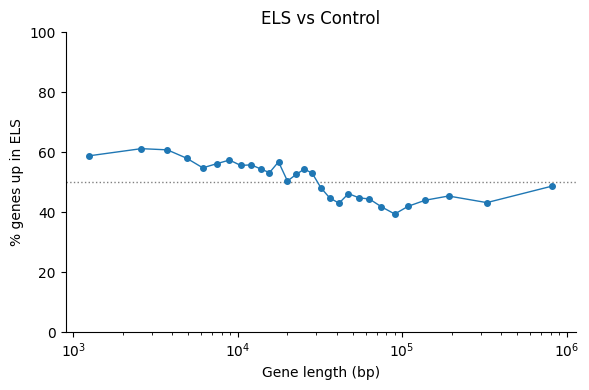

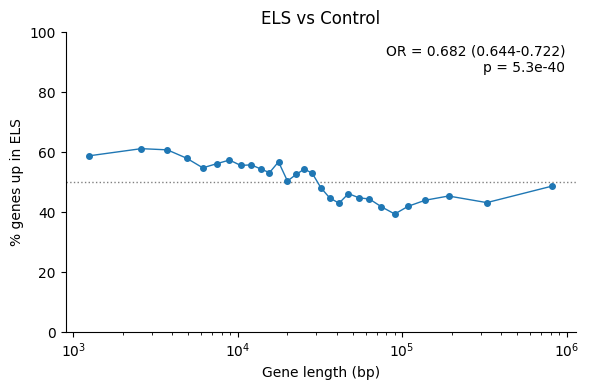

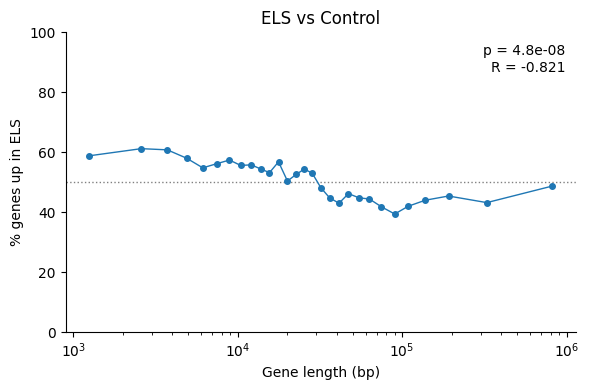

In [11]:
# % of genes up in `tested`, across bins of 500 genes sorted by length
fig, ax = glt.plot_gene_length_bins(results, bin_size=500, statistical_test=None)                    # No statistics
fig, ax = glt.plot_gene_length_bins(results, bin_size=500, statistical_test="odds_ratio")            # With odds ratio test
fig, ax = glt.plot_gene_length_bins(results, bin_size=500, statistical_test="linear_regression")     # With linear regression

/Users/ryan/anaconda3/lib/python3.11/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


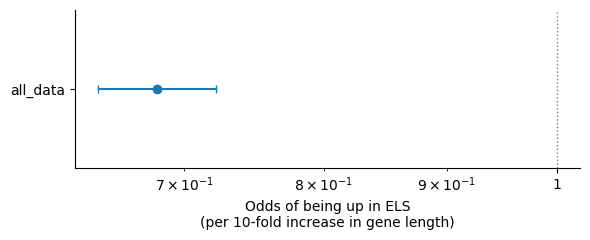

In [12]:
# Odds ratio with 95% CI per subset (most useful when using split_col)
fig, ax = glt.plot_gene_length_forest(results)